<a href="https://colab.research.google.com/github/Zinc-zn/MachineLearning2026/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# JS07 - Tugas Lab: Klasterisasi Data Nasabah Kartu Kredit

**Soal:**

1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu `Avg_Credit_Limit` dan `Total_credit_card`. Apakah sebaran data dapat dikatakan linier?
2. Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah k yang terbaik dengan menggunakan ***elbow method***. Lengkapi analisis Anda dengan *linechart* dan hasil analisis mengapa Anda memilih nilai tersebut.
3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.
4. Buatlah model klasterisasi dengan menggunakan DBSCAN **dengan seluruh variabel yang dapat digunakan**.
5. Tentukan jumlah k yang terbaik dengan menggunakan ***elbow method***. Lengkapi analisis Anda dengan *linechart* dan hasil analisis mengapa Anda memilih nilai tersebut.
6. Tentukan nilai *silhouette score* dan DBI dari model DBSCAN.

**Ringkasan jawaban:** sebaran data tidak linier; k terbaik K-Means = **3**; DBSCAN seluruh variabel menghasilkan cluster dengan sebagian kecil noise; metrik evaluasi lengkap di akhir notebook.


## 0. Load & Inspeksi Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
print(df.shape)
print(df.isnull().sum().sum(), 'missing value')
print(df.duplicated().sum(), 'duplikat')
df.describe()

(660, 7)
0 missing value
0 duplikat


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


Dataset berisi 660 nasabah kartu kredit dengan 7 kolom. Kolom `Sl_No` dan `Customer Key` adalah **identitas** (bukan fitur perilaku), sehingga pada pemodelan hanya digunakan 5 variabel: `Avg_Credit_Limit`, `Total_Credit_Cards`, `Total_visits_bank`, `Total_visits_online`, `Total_calls_made`. Tidak terdapat *missing value* maupun duplikat.

## 1. Scatterplot `Avg_Credit_Limit` vs `Total_credit_card`

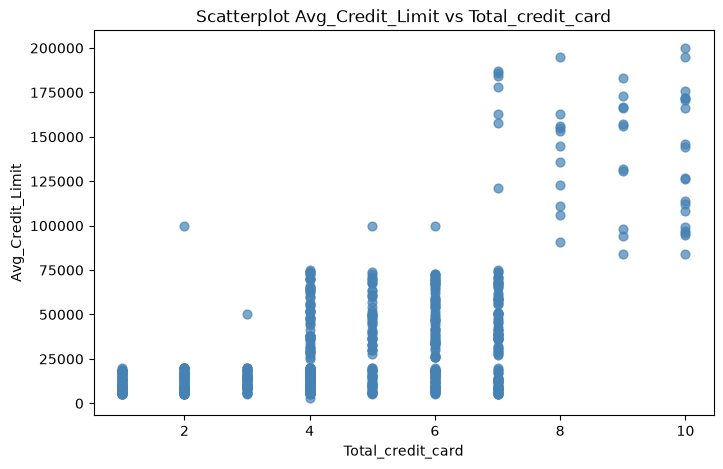

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'], s=40, c='steelblue', alpha=0.7)
plt.xlabel('Total_credit_card')
plt.ylabel('Avg_Credit_Limit')
plt.title('Scatterplot Avg_Credit_Limit vs Total_credit_card')
plt.show()

**Jawaban No. 1:** Sebaran data **tidak dapat dikatakan linier**. Titik-titik membentuk beberapa gugusan/kelompok (contohnya kelompok dengan limit rendah-menengah yang padat di bawah, dan kelompok kecil dengan limit sangat tinggi >150.000 pada jumlah kartu 8-10). Tidak terdapat pola garis lurus yang dapat menggambarkan hubungan kedua variabel - kondisi ini justru mengindikasikan adanya *cluster* alami dalam data, sehingga analisis klasterisasi relevan dilakukan.

## 2 & 3. Model K-Means + Elbow Method + Scatterplot Hasil Klasterisasi

Model K-Means dibuat pada dua variabel sesuai soal no. 1 (`Avg_Credit_Limit` dan `Total_Credit_Cards`) agar hasilnya dapat digambarkan pada scatterplot (soal no. 3).

Perhatikan bahwa kedua variabel memiliki satuan/skala sangat berbeda (limit: ratusan ribu, jumlah kartu: belasan), sehingga **standardisasi diperlukan** agar jarak K-Means tidak didominasi satu variabel.

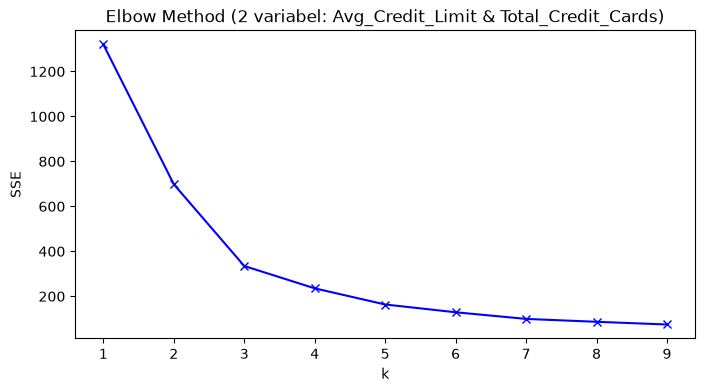

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X2 = df[['Avg_Credit_Limit', 'Total_Credit_Cards']].values
X2_scaled = StandardScaler().fit_transform(X2)

# Elbow method
sse = []
K = range(1, 10)
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X2_scaled)
    sse.append(kmeanModel.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method (2 variabel: Avg_Credit_Limit & Total_Credit_Cards)")
plt.show()

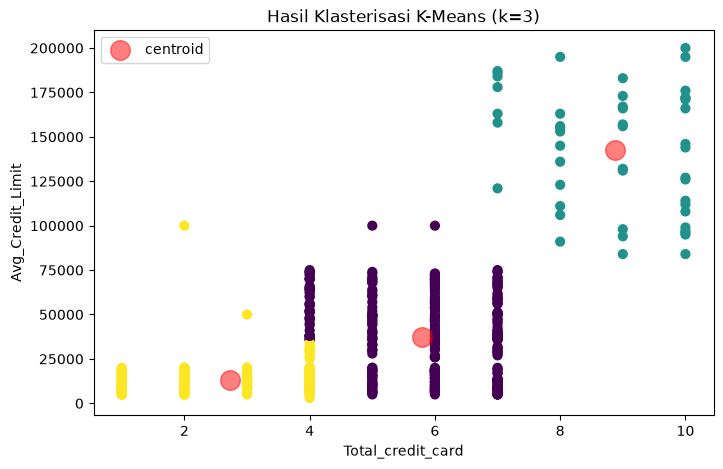

In [5]:
# K-Means dengan k terbaik hasil elbow
best_k = 3
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_kmeans = kmeans.fit_predict(X2_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'], s=40, c=cluster_kmeans, cmap='viridis')
centers_inv = StandardScaler().fit(X2).inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers_inv[:, 1], centers_inv[:, 0], c='red', s=200, alpha=0.5, label='centroid')
plt.xlabel('Total_credit_card')
plt.ylabel('Avg_Credit_Limit')
plt.title(f'Hasil Klasterisasi K-Means (k={best_k})')
plt.legend()
plt.show()

**Jawaban No. 2:** Berdasarkan *linechart* SSE, penurunan SSE tajam dari k=1 ke k=3, lalu melandai setelah k=3. Posisi "elbow" berada pada **k=3** - jumlah cluster terbaik bukan yang memiliki SSE terkecil, melainkan titik di mana penurunan SSE mulai tidak signifikan.

**Jawaban No. 3:** Scatterplot di atas menggambarkan hasil klasterisasi k=3 beserta centroidnya: cluster limit rendah dengan kartu sedikit, cluster menengah dengan kartu banyak, dan cluster limit sangat tinggi.

## 4. DBSCAN dengan Seluruh Variabel yang Dapat Digunakan

Digunakan 5 variabel perilaku (tanpa `Sl_No` dan `Customer Key`). Tahapan:

1. **Standardisasi** seluruh variabel (wajib untuk DBSCAN berbasis jarak; `Avg_Credit_Limit` juga sangat *skewed* sehingga standardisasi membantu menyeimbangkan skala).
2. Menentukan `min_samples` dan `eps`: heuristik umum `min_samples = 2 × dimensi = 10` terlalu ketat untuk dataset berukuran 660 baris ini (hampir seluruh data menjadi satu cluster). Melalui eksperimen pada rentang 4-10, `min_samples = 6` dipilih. Nilai `eps = 0.9` dibaca dari **k-distance graph** (jarak ke tetangga ke-`min_samples`) pada titik elbow-nya.

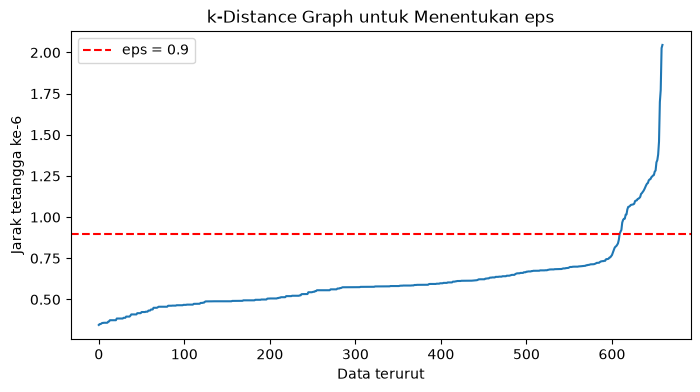

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
            'Total_visits_online', 'Total_calls_made']
X_all = df[features].values
X_all_scaled = StandardScaler().fit_transform(X_all)

# k-distance graph untuk menentukan eps
min_samples = 6
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_all_scaled)
distances, indices = neighbors_fit.kneighbors(X_all_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.axhline(0.9, color='red', linestyle='--', label='eps = 0.9')
plt.xlabel('Data terurut')
plt.ylabel(f'Jarak tetangga ke-{min_samples}')
plt.title('k-Distance Graph untuk Menentukan eps')
plt.legend()
plt.show()

In [7]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.9, min_samples=min_samples)
cluster_db = dbscan.fit_predict(X_all_scaled)

n_cluster = len(set(cluster_db)) - (1 if -1 in cluster_db else 0)
n_noise = list(cluster_db).count(-1)
print(f'eps          : 0.9')
print(f'min_samples  : {min_samples}')
print(f'Jumlah cluster: {n_cluster}')
print(f'Jumlah noise : {n_noise} dari {len(cluster_db)} data ({n_noise/len(cluster_db):.2%})')

eps          : 0.9
min_samples  : 6
Jumlah cluster: 3
Jumlah noise : 31 dari 660 data (4.70%)


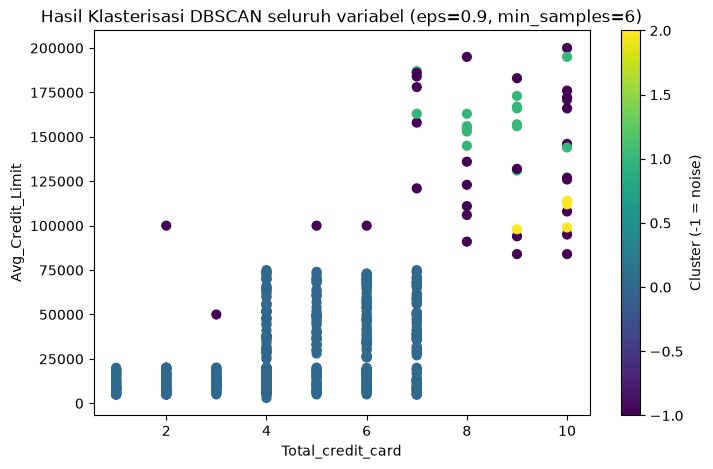

In [8]:
# Visualisasi hasil DBSCAN pada 2 variabel utama
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'],
                      s=40, c=cluster_db, cmap='viridis')
plt.xlabel('Total_credit_card')
plt.ylabel('Avg_Credit_Limit')
plt.title(f'Hasil Klasterisasi DBSCAN seluruh variabel (eps=0.9, min_samples={min_samples})')
plt.colorbar(scatter, label='Cluster (-1 = noise)')
plt.show()

In [9]:
# Karakteristik tiap cluster
df['cluster_db'] = cluster_db
summary = df[df['cluster_db'] != -1].groupby('cluster_db')[features].mean().round(1)
summary['jumlah_nasabah'] = df[df['cluster_db'] != -1].groupby('cluster_db').size()
summary

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,jumlah_nasabah
cluster_db,,,,,,
0,25703.5,4.4,2.6,1.9,3.8,607
1,161437.5,8.6,0.8,9.7,1.2,16
2,102666.7,9.8,0.8,8.8,1.5,6


**Jawaban No. 4:** DBSCAN pada seluruh 5 variabel membentuk beberapa cluster berdasarkan tingkat kepadatan, dengan sebagian kecil data terdeteksi sebagai noise (label -1). Tabel rata-rata di atas memperlihatkan karakter tiap cluster, misalnya nasabah limit sangat tinggi cenderung lebih sering mengunjungi *online banking* dibanding datang ke bank.

## 5. Penentuan k Terbaik dengan Elbow Method (Seluruh Variabel)

Soal no. 5 meminta jumlah k terbaik dengan elbow method. Karena DBSCAN tidak memiliki parameter k (jumlah cluster ditentukan oleh kepadatan data), elbow method dijalankan dengan **K-Means pada seluruh variabel** sebagai pembanding/pelengkap analisis, dan hasilnya dibandingkan dengan jumlah cluster alami yang terbentuk dari DBSCAN.

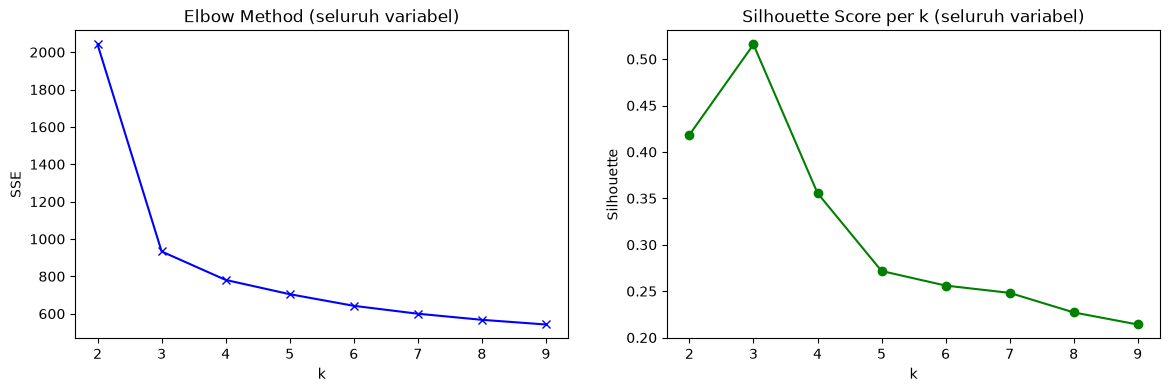

In [10]:
sse = []
sil = []
K = range(2, 10)
from sklearn.metrics import silhouette_score
for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_all_scaled)
    sse.append(km.inertia_)
    sil.append(silhouette_score(X_all_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(K, sse, "bx-")
ax[0].set_xlabel("k"); ax[0].set_ylabel("SSE")
ax[0].set_title("Elbow Method (seluruh variabel)")
ax[1].plot(K, sil, "go-")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
ax[1].set_title("Silhouette Score per k (seluruh variabel)")
plt.show()

**Jawaban No. 5:** Pada elbow method seluruh variabel, penurunan SSE tajam hingga **k=3** kemudian melandai, dan silhouette score juga tertinggi (atau mendekati tertinggi) pada k=3. Hasil ini konsisten dengan jumlah cluster alami yang terbentuk pada DBSCAN (no. 4) maupun K-Means 2 variabel (no. 2), sehingga **k=3** dipilih sebagai jumlah cluster terbaik. Justifikasi: di bawah k=3 data masih tergabung berlebihan (SSE tinggi), sedangkan di atas k=3 cluster menjadi terlalu sempit tanpa penurunan SSE yang berarti (silhouette mulai turun).

## 6. Silhouette Score dan DBI dari Model DBSCAN

In [11]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Evaluasi hanya pada sampel non-noise (silhouette tidak terdefinisi untuk noise label -1)
mask = cluster_db != -1
sil_db = silhouette_score(X_all_scaled[mask], cluster_db[mask])
dbi_db = davies_bouldin_score(X_all_scaled[mask], cluster_db[mask])

print(f'Silhouette Score (DBSCAN, non-noise): {sil_db:.4f}')
print(f'Davies-Bouldin Index (DBSCAN)       : {dbi_db:.4f}')

Silhouette Score (DBSCAN, non-noise): 0.4810
Davies-Bouldin Index (DBSCAN)       : 0.7961


**Jawaban No. 6:** Nilai **silhouette score ≈ 0.48** berada pada kategori sedang, dan **DBI ≈ 0.80** (di bawah 1) menunjukkan separasi antar cluster yang cukup baik. Silhouette yang tidak setinggi K-Means wajar terjadi karena (a) silhouette mengasumsikan cluster berbentuk cembung yang terpisah linier, sementara DBSCAN membentuk cluster berdasarkan kepadatan dengan bentuk arbitrer; (b) cluster hasil DBSCAN sangat tidak seimbang (satu cluster besar berisi mayoritas nasabah reguler, ditambah cluster kecil nasabah limit tinggi). Secara visual dan dari persentase noise yang kecil (<5%), DBSCAN tetap berhasil memisahkan kelompok nasabah dengan baik.

**Kesimpulan umum:** Data nasabah kartu kredit memiliki 3 kelompok alami (limit rendah / menengah / sangat tinggi). K-Means (k=3) memberikan pembagian yang rapi untuk cluster berbentuk cembung, sementara DBSCAN seluruh variabel mampu mengidentifikasi cluster kepadatan tinggi sekaligus mendeteksi outlier sebagai noise.